# Verificación sistemática de la tesis Christoffel–Darboux
**Versión 1 · 19 noviembre 2026 · base Git `3f1b5be`**

Esta notebook es un cuaderno de laboratorio: cada sección contiene **pregunta → supuesto → ejecución → criterio → interpretación**. Ejecuta en orden con **Restart Kernel and Run All**. Primero `MODE="smoke"`; luego `MODE="full"` y desarrollo; congela decisiones antes del test de ModelNet.

**No es una réplica de A8.** El repositorio actualizado usa otras familias sintéticas, escalado, métrica y perturbaciones. No exigir que sus cifras coincidan con A8. ModelNet10 y ModelNet40 son evaluaciones separadas y contienen categorías/objetos relacionados: no usarlos como conjuntos independientes sin auditar solapamientos.

Tareas: **A** soporte; **B** partición de puntos; **C** embeddings de objetos, recuperación y clustering; **D** reconstrucción aproximada. Un buen resultado en C no valida B ni D.

Fuentes: documento adjunto *Documento base de tesis CD*, §§2,4–6; *Evaluación metodológica y experimental*, 12 nov; código de point-field en el commit indicado. Se conservan resultados nuevos por separado. Los archivos auxiliares deben estar en `benchmarks/` dentro del repositorio parcheado.

## 0. Instalación (una vez)
Desde la raíz del repositorio: `python -m pip install -e ".[notebook,dev]"`. Reinicia el kernel después. Opcional para el benchmark histórico completo: `python -m pip install -e ".[bench]"`. No instalamos paquetes automáticamente en celdas de análisis.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, platform, subprocess, time, warnings
from datetime import datetime, timezone
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/pointfield').is_dir()), None)
assert ROOT is not None, 'Abre la notebook dentro del repositorio point-field'
sys.path.insert(0,str(ROOT/'src')); sys.path.insert(0,str(ROOT/'benchmarks'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
LIMIT = threadpool_limits(limits=1)  # reduce variación y sobreuso de BLAS
from notebook_tools import *
from pointfield.learning import ChristoffelDarboux, CDDescriptor, MultiViewMetric
from pointfield.learning.christoffel import monomial_exponents, monomial_weights, monomial_basis
from pointfield.objects import make_object_dataset, random_similarity
from pointfield.learning.invariant import normalize_similarity
MODE = 'smoke'  # full para resultados de tesis, smoke sólo verifica ejecución
SEED = 20261119
N_POINTS = 96 if MODE == 'smoke' else 512
N_BOOT = 100 if MODE == 'smoke' else 3000
SEEDS = [100] if MODE == 'smoke' else [100,101,102,103,104]
MODELNET10_ROOT = None  # ejemplo: Path('/home/isaac/datasets/ModelNet10')
MODELNET40_ROOT = None  # ejemplo: Path('/home/isaac/datasets/ModelNet40')
RUN_MODELNET = False
EVALUATION_SPLIT = 'validation'  # cambiar a test sólo tras congelar decisiones
ALLOW_FINAL_TEST = False
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = ROOT/'runs'/RUN_ID; OUT.mkdir(parents=True,exist_ok=False)
config = dict(protocol=PROTOCOL,mode=MODE,seed=SEED,n_points=N_POINTS,n_boot=N_BOOT,seeds=SEEDS,
              split=EVALUATION_SPLIT,run_modelnet=RUN_MODELNET,allow_test=ALLOW_FINAL_TEST)
(OUT/'config.json').write_text(json.dumps(config,indent=2))
print('Salidas:',OUT)
print('Modo:', MODE, '| NO atribuir smoke a resultados definitivos')

Salidas: /workspace/scratch/300c1df4e8f8/point-field/runs/20261119T180453630243Z
Modo: smoke | NO atribuir smoke a resultados definitivos


## 1. Procedencia, entorno y regresiones
**Pregunta:** ¿qué código produjo cada tabla? Guardamos versiones, commit y hashes del código modificado; el SHA del commit solo no identifica un árbol sucio. Se ejecutan las pruebas del repositorio. Un fallo bloquea las secciones siguientes: no lo ocultes con `try/except`.

El auditor de cifras comprueba texto frente a CSV conservados, **no** vuelve a ejecutar los experimentos históricos.

In [2]:
import importlib.metadata as metadata
versions={p:metadata.version(p) for p in ['numpy','scipy','scikit-learn','pandas','matplotlib','nbformat','pytest']}
try: commit=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip()
except subprocess.CalledProcessError: commit='sin git'
hashes={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
        for folder in ['src','benchmarks','tests'] for p in (ROOT/folder).rglob('*.py')}
(OUT/'environment.json').write_text(json.dumps(dict(python=sys.version,platform=platform.platform(),
                            packages=versions,commit=commit,source_sha256=hashes),indent=2))
r=subprocess.run([sys.executable,'-m','pytest','-q'],cwd=ROOT,text=True,capture_output=True)
print(r.stdout); print(r.stderr)
(OUT/'pytest.txt').write_text(r.stdout+r.stderr)
assert r.returncode==0, 'Corregir pruebas antes de continuar'
r=subprocess.run([sys.executable,'benchmarks/verificar_cifras.py'],cwd=ROOT,text=True,capture_output=True)
(OUT/'historical_consistency.txt').write_text(r.stdout+r.stderr)
print(r.stdout[-700:]); assert r.returncode==0
pd.Series(versions)

........................................................................ [ 70%]
..............................                                           [100%]
=============================== warnings summary ===============================
../../../../opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/anyio/pytest_plugin.py:14
  /opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/anyio/pytest_plugin.py:14: PytestRemovedIn10Warning: _pytest.python.CallSpec2 has been renamed to CallSpec.
  The CallSpec2 alias will be removed in pytest 10.
  Update imports to use CallSpec instead.
  See https://docs.pytest.org/en/stable/deprecations.html#callspec2-renamed
    from _pytest.python import CallSpec2

tests/test_learning.py::test_local_spectral_runs
  /opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:324: UserWarning: Graph is not fully

## 2. Matemática visible: de puntos a energía polinomial
Para la medida empírica, integrar es promediar: $M=V^TV/N$. No es una covarianza insesgada; no usar $N-1$. La base ponderada usa $sqrt{k!/alpha!}$, por lo que su producto interno por grado es $(x^Ty)^k$.

**Criterio:** comparar la matriz y score 1D con un ejemplo calculable a mano. Para $X=(-1,0,1)$ y grado 2: $q(x)=3-4.5x^2+4.5x^4$. Orden de base: $(1,x,x^2)$. El score crece fuera del soporte; $Lambda=1/q$, no una densidad normalizada.

,1,x,x²
0,1.0,-1.0,1.0
1,1.0,0.0,0.0
2,1.0,1.0,1.0


,0,1,2
0,1.000000,0.000000,0.666667
1,0.000000,0.666667,0.000000
2,0.666667,0.000000,0.666667


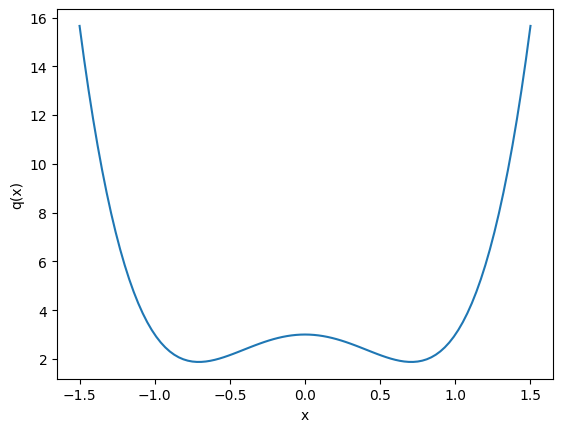

In [3]:
X=np.array([[-1.],[0.],[1.]])
cd=ChristoffelDarboux(2,reg=0,basis='weighted').fit(X)
display(pd.DataFrame(cd.design(X),columns=['1','x','x²']))
display(pd.DataFrame(cd.moment_matrix_))
z=np.linspace(-1.5,1.5,101)[:,None]
assert np.allclose(cd.score(z),3-4.5*z[:,0]**2+4.5*z[:,0]**4)
plt.plot(z[:,0],cd.score(z));plt.xlabel('x');plt.ylabel('q(x)');plt.show()
# Identidad variacional: coeficientes óptimos a = A^{-1}v/q.
v=cd.design(np.array([[.3]]))[0];a=np.linalg.solve(cd.M_reg_,v);a/=v@a
assert np.isclose(a@v,1)
assert np.isclose(a@cd.M_reg_@a,cd.christoffel(np.array([[.3]]))[0])

## 3. Singularidad, ridge y traza
Una circunferencia cumple $x^2+y^2-1=0$ y tiene rango 5, aunque $N>6$. La pseudoinversa elimina esa ecuación. Con ridge se conserva como penalización.

**Criterios:** rango 5; score central ridge mayor que el de la curva; media de score igual al grado de libertad efectivo $sum_jeta_j/(eta_j+epsilon)$, **no** igual a 6. Con pesos, usar la media ponderada. Estas son verificaciones numéricas de identidades, no garantías estadísticas.

In [4]:
t=np.linspace(0,2*np.pi,256,endpoint=False);X=np.c_[np.cos(t),np.sin(t)]
cd=ChristoffelDarboux(2,reg=.01,basis='weighted').fit(X)
v=cd.design(np.zeros((1,2)))
qpinv=(v@np.linalg.pinv(cd.moment_matrix_)@v.T).item()
checks={'rank':np.linalg.matrix_rank(cd.moment_matrix_,tol=1e-10),'basis':cd.basis_size_,
        'q_center_ridge':cd.score(np.zeros((1,2)))[0],'q_center_pinv':qpinv,
        'mean_score':cd.score(X).mean(),'effective_dof':cd.effective_dof_}
assert checks['rank']==5
assert checks['q_center_ridge']>cd.score(X).mean()
assert np.isclose(checks['mean_score'],checks['effective_dof'],rtol=1e-10)
display(pd.Series(checks))
w=np.arange(1,len(X)+1,dtype=float);w/=w.sum()
weighted=ChristoffelDarboux(2,reg=.01,basis='weighted').fit(X,w)
assert np.isclose(w@weighted.score(X),weighted.effective_dof_,rtol=1e-9)

rank               5.000000
basis              6.000000
q_center_ridge    67.109635
q_center_pinv      0.444444
mean_score         4.937660
effective_dof      4.937660
dtype: float64

## 4. Invariancia y sus límites
Transforma **los mismos puntos**, sin remuestrear. Prueba traslación, escala, rotación/reflexión y permutación. El descriptor es O(d)-invariante y pierde quiralidad. La submuestra de pares rompe invariancia exacta a permutaciones; mantenemos N≤512 (todos los pares). El bloque angular y las matrices de pares cuestan O(N²); no subir a decenas de miles de puntos sin cambiar implementación.

**Criterio:** error relativo <1e-8 en float64. Cambiar densidad, ruido o cantidad de puntos se evalúa después como robustez.

In [5]:
inv=[]
for dim in (2,3):
    clouds,_,families=make_object_dataset(dim,1,N_POINTS,seed=SEED)
    rng=np.random.default_rng(SEED)
    for family,X in zip(families,clouds):
        Y=random_similarity(X,rng)[rng.permutation(len(X))]
        for name,f in [('CD',CDDescriptor()),('M',moment_descriptor),('D2_exact',exact_d2)]:
            a,b=f(X),f(Y);err=np.linalg.norm(a-b)/max(np.linalg.norm(a),1e-12)
            inv.append(dict(dim=dim,family=family,method=name,relative_error=err))
inv=pd.DataFrame(inv);inv.to_csv(OUT/'invariance.csv',index=False)
display(inv);assert inv.relative_error.max()<1e-8

,dim,family,method,relative_error
0,2,ellipse,CD,1.294238e-15
1,2,ellipse,M,6.311672e-16
2,2,ellipse,D2_exact,0.000000e+00
3,2,rectangle,CD,3.123981e-15
4,2,rectangle,M,1.323575e-15
5,2,rectangle,D2_exact,0.000000e+00
6,2,triangle,CD,6.685273e-15
7,2,triangle,M,1.380656e-14
8,2,triangle,D2_exact,0.000000e+00
9,2,hexagon,CD,3.569919e-15


## 5. Soporte con calibración independiente: tarea A
Entrenamiento, calibración y consultas separados. Para α=0.05, umbral conformal con índice ceil((m+1)(1−α)); infinito si excede m. La garantía es marginal bajo intercambiabilidad, no de IoU ni de cobertura condicional. El anillo de evaluación se muestrea uniforme en área.

**Criterio:** observar cobertura y falsos positivos en el hueco/exterior; comparar grados. No elegir grado usando este test. Esta ejecución es diagnóstica; congelar el grado en otro conjunto si se reporta como confirmatoria.

In [6]:
from pointfield.geometry.shapes2d import Annulus
from sklearn.metrics import roc_auc_score
shape=Annulus(.5,1.)
train=shape.sample(400,seed=1);cal=shape.sample(200,seed=2);test=shape.sample(500,seed=3)
rng=np.random.default_rng(4);outside=rng.uniform(-1.5,1.5,(2000,2))
radius=np.linalg.norm(outside,axis=1);outside=outside[(radius<.5)|(radius>1)]
support=[]
for degree in (1,2,4,6):
    model=ChristoffelDarboux(degree,.01,basis='weighted').fit(train)
    scores=np.sort(model.score(cal));j=int(np.ceil((len(cal)+1)*.95))
    threshold=np.inf if j>len(cal) else scores[j-1]
    good,bad=model.score(test),model.score(outside)
    support.append(dict(degree=degree,coverage=np.mean(good<=threshold),false_accept=np.mean(bad<=threshold),
        AUROC=roc_auc_score(np.r_[np.zeros(len(good)),np.ones(len(bad))],np.r_[good,bad]),
        cond_A=np.linalg.cond(model.M_reg_),effective_dof=model.effective_dof_))
support=pd.DataFrame(support);support.to_csv(OUT/'support.csv',index=False);display(support)

,degree,coverage,false_accept,AUROC,cond_A,effective_dof
0,1,0.966,0.120245,0.880981,3.145339,2.960881
1,2,0.952,0.118886,0.964389,52.882707,5.763461
2,4,0.932,0.118886,0.965216,623.836246,12.478812
3,6,0.926,0.118886,0.965026,1176.816906,18.310112


## 6. Agrupar puntos: tarea B, benchmark 2D
Se reutilizan escenarios y modelos públicos con semillas declaradas. K verdadero se proporciona sólo a los métodos que lo requieren. Guardamos ARI, K obtenido, ruido y tiempo. La fase llamada “Szegő” en la API es una transformación especializada para espirales, no una implementación general de la teoría de Szegő.

`smoke` usa menos puntos y tres métodos para verificar flujo; `full` ejecuta los seis escenarios, cuatro perturbaciones y todos los métodos de `common.METHODS`. El warning de grafo desconectado es evidencia relevante; no ocultarlo globalmente.

In [7]:
import common
warnings.resetwarnings()
from pointfield.datasets import make, SCENARIOS, HELD_OUT
from pointfield.perturbations import PERTURBATIONS
from sklearn.metrics import adjusted_rand_score
selected=['K-Means','DBSCAN','CD local-espectral (mejora 1)'] if MODE=='smoke' else list(common.METHODS)
point_rows=[]
for case in (['compacto','anidado'] if MODE=='smoke' else list(SCENARIOS)+list(HELD_OUT)):
    for variant in (['base'] if MODE=='smoke' else common.VARIANTS):
        for seed in SEEDS:
            ds=make(case,n_per_group=40 if MODE=='smoke' else 150,seed=seed)
            if variant!='base':ds=PERTURBATIONS[variant](ds,seed+1000)
            ds=ds.normalized()
            for name in selected:
                factory,needs_k,_,_=common.METHODS[name];start=time.perf_counter()
                lab=factory(ds.n_groups).fit_predict(ds.X)
                point_rows.append(dict(case=case,variant=variant,seed=seed,method=name,K_given=needs_k,
                    ARI=adjusted_rand_score(ds.y,lab),K_est=len(set(lab)-{-1}),noise_fraction=np.mean(lab==-1),
                    seconds=time.perf_counter()-start))
point_results=pd.DataFrame(point_rows);point_results.to_csv(OUT/'point_clustering.csv',index=False)
display(point_results.groupby('method')[['ARI','seconds','noise_fraction']].mean())

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thr

,ARI,seconds,noise_fraction
method,,,
CD local-espectral (mejora 1),0.654619,0.023123,0.000000
DBSCAN,0.821732,0.006314,0.272917
K-Means,0.452787,0.012828,0.000000


## 7. Embeddings de puntos ≠ descriptores de objetos
Aquí se enrolla un escenario 2D en 3D y se intenta recuperar su geometría latente. T y continuidad se calculan respecto del 2D original, no de clases ni de un gráfico t-SNE. Los métodos ven sólo la nube 3D. Comparación transductiva: no demuestra generalización a nuevas nubes.

In [8]:
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import Isomap, SpectralEmbedding, trustworthiness
from pointfield.transforms import embed_roll
from pointfield.learning import CDLocalSpectral
embedding_rows=[]
for seed in SEEDS:
    ds=make('no_convexo',n_per_group=50 if MODE=='smoke' else 150,seed=seed)
    latent=ds.latent;X=normalize_similarity(embed_roll(latent))[0]
    methods={'PCA':PCA(2),'KernelPCA':KernelPCA(2,kernel='rbf'),'Isomap':Isomap(n_neighbors=10,n_components=2),
             'Laplacian':SpectralEmbedding(n_components=2,n_neighbors=10,random_state=seed)}
    if MODE=='full':
        import umap
        methods['UMAP']=umap.UMAP(n_neighbors=10,n_components=2,random_state=seed)
    E={name:model.fit_transform(X) for name,model in methods.items()}
    E['CD_local']=CDLocalSpectral(n_neighbors=10).embed(X,2)
    for name,z in E.items():
        embedding_rows.append(dict(seed=seed,method=name,T=trustworthiness(latent,z,n_neighbors=10),
                                  continuity=trustworthiness(z,latent,n_neighbors=10)))
embedding_results=pd.DataFrame(embedding_rows);embedding_results.to_csv(OUT/'point_embeddings.csv',index=False)
display(embedding_results.groupby('method')[['T','continuity']].mean())

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thr

,T,continuity
method,,
CD_local,0.776959,0.921751
Isomap,0.762864,0.943172
KernelPCA,0.778095,0.941018
Laplacian,0.790367,0.936769
PCA,0.838757,0.952544


## 8. Objetos 2D/3D: tarea C
Se mantienen separados referencia (ajuste), validación (decisiones) y test. **El smoke no selecciona ganadores.** Las familias actuales son seis en 2D y siete en 3D; no coinciden con las seis de A8. Algunas familias (esfera, cubo, hexágono) tienen geometría fija: sus réplicas prueban remuestreo y pose, no generalización a nuevas formas.

Controles: momentos, D2 exacto y espectro de covarianza. CD y momentos con/sin métrica. La métrica no recibe categorías; selecciona η por identidad de vistas dentro de referencia. Su escalador interno sólo ve identidades de ajuste. Se favorece mayor regularización en empates.

mAP y 1-NN usan clases sólo como sondas. KMeans sobre queries recibe K verdadero; ARI no significa estimación automática de K. Bootstrap por objeto, con entrenamiento fijo.

In [9]:
datasets={};objects={};models_by_dataset={};summaries=[]
for dim in (2,3):
    nr,nv,nt=(3,2,2) if MODE=='smoke' else (30,10,20)
    R,yr,fam=make_object_dataset(dim,nr,N_POINTS,seed=SEED)
    V,yv,_=make_object_dataset(dim,nv,N_POINTS,seed=SEED+1)
    Q,yq,_=make_object_dataset(dim,nt,N_POINTS,seed=SEED+2)
    name=f'synthetic_{dim}d';datasets[name]=(R,yr,V,yv,Q,yq)
    print(name, fam, '| reference/validation/test:',len(R),len(V),len(Q))
    models,timing=fit_models(R,SEED,n_views=2 if MODE=='smoke' else 4)
    models_by_dataset[name]=models
    ids=[f'{name}_test_{i}' for i in range(len(Q))]
    summary,individual,ci,Z=evaluate(models,Q,yq,yr,ids,seed=SEED,n_boot=N_BOOT)
    summary['dataset']=name;summaries.append(summary)
    individual.to_csv(OUT/f'{name}_per_object.csv',index=False)
    timing.to_csv(OUT/f'{name}_fit_time.csv',index=False)
    (OUT/f'{name}_bootstrap.json').write_text(json.dumps(ci,indent=2))
    save_metric_state(models,OUT/f'{name}_state.npz')
    objects[name]=(ids,Z)
object_results=pd.concat(summaries,ignore_index=True);object_results.to_csv(OUT/'object_results.csv',index=False)
display(object_results)

synthetic_2d ['ellipse', 'rectangle', 'triangle', 'hexagon', 'star', 'annulus'] | reference/validation/test: 18 12 12
synthetic_3d ['sphere', 'ellipsoid', 'cube', 'cylinder', 'cone', 'torus', 'pyramid'] | reference/validation/test: 21 14 14


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thr

,method,mAP,nn,ARI,ARI_seed_sd,AMI,K_given,dataset
0,CD_U,0.836607,1.000000,0.625850,0.000000,0.736000,6,synthetic_2d
1,CD_U_metric,0.840149,1.000000,0.625850,0.000000,0.736000,6,synthetic_2d
2,CD_W,0.844910,0.916667,0.625850,0.000000,0.736000,6,synthetic_2d
3,M_U,0.769372,0.750000,0.499215,0.089545,0.601862,6,synthetic_2d
4,M_U_metric,0.760935,0.666667,0.453828,0.121639,0.579050,6,synthetic_2d
5,D2_exact,0.656086,0.750000,0.377577,0.036096,0.411800,6,synthetic_2d
6,PCA_spectrum,0.385424,0.250000,-0.115942,0.000000,-0.128717,6,synthetic_2d
7,CD_U,0.816095,0.857143,0.676617,0.000000,0.777143,7,synthetic_3d
8,CD_U_metric,0.824606,0.857143,0.676617,0.000000,0.777143,7,synthetic_3d
9,CD_W,0.861054,0.928571,0.676617,0.000000,0.777143,7,synthetic_3d


## 9. Ablación angular y robustez
El bloque angular puede explicar la mejora. Volver a ajustar CD/momentos sin él compara modelos completos, no aísla causalmente cada coordenada. Todos reciben exactamente las mismas queries perturbadas. Densidad y submuestreo reducen N a la mitad: su comparación ayuda a separar ambos efectos.

`full`: tres repeticiones por objeto. Promediar AP por objeto antes de bootstrap; nunca contar cada vista como un objeto independiente. Estas perturbaciones son **protocolo nuevo v1**, no las del script histórico.

In [10]:
name='synthetic_3d';R,yr,V,yv,Q,yq=datasets[name]
noangular,_=fit_models(R,SEED,angular=False,n_views=2 if MODE=='smoke' else 4)
ablation,_,_,_=evaluate(noangular,Q,yq,yr,objects[name][0],seed=SEED,n_boot=N_BOOT)
ablation['angular']=False;ablation.to_csv(OUT/'ablation_no_angular.csv',index=False)
display(ablation)
robust=[]
for condition in ['clean','noise','density','subsample','occlusion','outliers']:
    for rep in range(1 if MODE=='smoke' else 3):
        pert=[perturb_cloud(x,condition,stable_seed(SEED,f'{condition}:{rep}:{i}')) for i,x in enumerate(Q)]
        _,individual,_,_=evaluate(models_by_dataset[name],pert,yq,yr,objects[name][0],seed=SEED,n_boot=20,cluster_seeds=(0,))
        individual['condition']=condition;individual['repeat']=rep;robust.append(individual)
robust=pd.concat(robust);robust.to_csv(OUT/'robustness_individual.csv',index=False)
means=robust.groupby(['condition','method','object_id','label'],as_index=False).AP.mean()
display(means.groupby(['condition','method']).AP.mean().unstack())
ci_rows=[]
for condition,g in means.groupby('condition'):
    wide=g.pivot(index=['object_id','label'],columns='method',values='AP')
    ci=paired_bootstrap(wide.CD_U_metric,wide.M_U_metric,strata=wide.index.get_level_values('label'),n_boot=N_BOOT,seed=SEED)
    ci_rows.append(dict(condition=condition,**ci))
pd.DataFrame(ci_rows).to_csv(OUT/'robustness_paired_ci.csv',index=False)

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thr

,method,mAP,nn,ARI,ARI_seed_sd,AMI,K_given,angular
0,CD_U,0.852089,0.857143,0.676617,0.000000e+00,0.777143,7,False
1,CD_U_metric,0.852089,0.857143,0.676617,0.000000e+00,0.777143,7,False
2,CD_W,0.904106,1.000000,0.690476,1.110223e-16,0.690476,7,False
3,M_U,0.824684,0.928571,0.589474,0.000000e+00,0.644369,7,False
4,M_U_metric,0.844327,1.000000,0.589474,0.000000e+00,0.644369,7,False
5,D2_exact,0.694122,0.857143,0.676617,0.000000e+00,0.777143,7,False
6,PCA_spectrum,0.560628,0.642857,0.141509,0.000000e+00,0.168628,7,False


method,CD_U,CD_U_metric,CD_W,D2_exact,M_U,M_U_metric,PCA_spectrum
condition,,,,,,,
clean,0.816095,0.824606,0.861054,0.694122,0.773384,0.778118,0.560628
density,0.542009,0.535702,0.508259,0.533670,0.540396,0.570738,0.390022
noise,0.787751,0.808704,0.834269,0.679457,0.769416,0.782681,0.563867
occlusion,0.665441,0.670094,0.688973,0.621104,0.584386,0.631455,0.483391
outliers,0.299799,0.308102,0.282325,0.292835,0.292425,0.295085,0.342653
subsample,0.765719,0.777572,0.763240,0.547887,0.653523,0.710275,0.495305


## 10. ModelNet10 y ModelNet40 locales
Configura las rutas de la primera celda y `RUN_MODELNET=True`, reinicia y ejecuta. Este adaptador acepta la distribución de **mallas OFF** `<raíz>/<clase>/train/*.off` y `test/*.off`. Si descargaste TXT de puntos/normales o HDF5, se detiene: no confundir los formatos ni inferir splits por posición.

Se registra SHA-256, ruta, clase, split oficial y semilla por malla. Se eliminan duplicados binarios entre train/test, priorizando train, y se guardan exclusiones. SHA-256 no detecta duplicados geométricos serializados de otra manera. Muestreo uniforme por área; triangulación en abanico presupone caras triangulares/convexas. Inspeccionar mallas problemáticas.

Primero usar validation. Para test se exige `ALLOW_FINAL_TEST=True`. Antes de activarlo guarda este notebook/configuración en Git y fija métodos/η/grado/decoder. ModelNet40 es una ampliación exploratoria; no una prueba ciega si contiene objetos ya usados de ModelNet10. El presupuesto por clase es nuevo, no S1/S2/S3.

In [11]:
modelnet_summaries=[];manifests={}
if not RUN_MODELNET:
    print('PENDIENTE: ModelNet local no configurado. No se generan resultados ficticios.')
else:
    assert EVALUATION_SPLIT in ('validation','test')
    assert EVALUATION_SPLIT!='test' or ALLOW_FINAL_TEST, 'Congela decisiones y habilita el test explícitamente'
    assert MODELNET10_ROOT is not None or MODELNET40_ROOT is not None
    for name,root,nclasses in [('modelnet10',MODELNET10_ROOT,10),('modelnet40',MODELNET40_ROOT,40)]:
        if root is None:continue
        indexed,rejected=modelnet_manifest(root,nclasses)
        manifest=freeze_splits(indexed,SEED,(3,2,2) if MODE=='smoke' else (40,10,20))
        manifest.to_csv(OUT/f'{name}_manifest.csv',index=False)
        rejected.to_csv(OUT/f'{name}_excluded.csv',index=False);manifests[name]=manifest
        R,yr,_=load_partition(manifest,'reference',N_POINTS)
        Q,yq,ids=load_partition(manifest,EVALUATION_SPLIT,N_POINTS)
        models,timing=fit_models(R,SEED,n_views=2 if MODE=='smoke' else 4)
        summary,individual,ci,Z=evaluate(models,Q,yq,yr,ids,seed=SEED,n_boot=N_BOOT)
        summary['dataset']=name;summary['split']=EVALUATION_SPLIT;modelnet_summaries.append(summary)
        summary.to_csv(OUT/f'{name}_summary.csv',index=False)
        individual.to_csv(OUT/f'{name}_per_object.csv',index=False)
        timing.to_csv(OUT/f'{name}_time.csv',index=False)
        save_metric_state(models,OUT/f'{name}_state.npz')
        (OUT/f'{name}_bootstrap.json').write_text(json.dumps(ci,indent=2))
        display(summary)
        # El decoder sólo evalúa test cuando hay validación separada.
        if EVALUATION_SPLIT=='test':
            V,yv,_=load_partition(manifest,'validation',N_POINTS)
            datasets[name]=(R,yr,V,yv,Q,yq)
            models_by_dataset[name]=models;objects[name]=(ids,Z)
    if len(manifests)==2:
        a,b=manifests.values();overlap=a.merge(b,on='sha256',suffixes=('_10','_40'))
        overlap.to_csv(OUT/'modelnet10_40_overlap.csv',index=False)
        print('Solapamientos binarios ModelNet10/40:',len(overlap))

PENDIENTE: ModelNet local no configurado. No se generan resultados ficticios.


## 10b. Escenas 3D: prueba nueva, con y sin K conocido
Una escena contiene esfera, cubo y toro a distancias controladas. Se comparan CD local y afinidad binaria sobre **el mismo grafo kNN**; DBSCAN usa la rodilla sin conocer K. No es una réplica de CD-barrera. Los puntos son unidades de partición, pero la **escena** es unidad estadística. Dos distancias y una semilla en smoke no justifican superioridad.

El grado local 1 es una variante de covarianza/Mahalanobis, no evidencia de ventaja de polinomios de alto grado. La afinidad local del código histórico usa coordenadas sin centrar por vecindario: no extrapolar las pruebas de invariancia del descriptor global a este método.

In [12]:
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import SpectralClustering
from pointfield.geometry.shapes3d import Sphere,Cube,Torus
from pointfield.learning.clustering import local_cd_affinity
scene_rows=[]
for seed in SEEDS:
    for gap in [1.3,3.0]:
        clouds=[Sphere(.5).sample(50 if MODE=='smoke' else 150,seed=seed),
                Cube(1.).sample(50 if MODE=='smoke' else 150,seed=seed+1),
                Torus(.5,.2).sample(50 if MODE=='smoke' else 150,seed=seed+2)]
        X=np.vstack([x+np.array([i*gap,0,0]) for i,x in enumerate(clouds)])
        y=np.repeat(np.arange(3),len(clouds[0]));X=normalize_similarity(X)[0]
        A=local_cd_affinity(X,n_neighbors=10,degree=1)
        G=kneighbors_graph(X,10,mode='connectivity',include_self=False).toarray();G=np.maximum(G,G.T)
        # Vecinos empatan a veces; las primitivas muestreadas evitan empates exactos habituales.
        assert np.array_equal(A>0,G>0), 'Las afinidades deben compartir aristas'
        labels={'Spatial_Kgiven':SpectralClustering(3,affinity='precomputed',random_state=seed).fit_predict(G),
                'CD_local_Kgiven':SpectralClustering(3,affinity='precomputed',random_state=seed).fit_predict(A),
                'DBSCAN_Kunknown':common.DBSCANKnee().fit_predict(X)}
        for name,lab in labels.items():scene_rows.append(dict(seed=seed,gap=gap,method=name,
            ARI=adjusted_rand_score(y,lab),K_est=len(set(lab)-{-1}),noise_fraction=np.mean(lab==-1)))
scene_results=pd.DataFrame(scene_rows);scene_results.to_csv(OUT/'scenes_3d.csv',index=False);display(scene_results)

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thr

,seed,gap,method,ARI,K_est,noise_fraction
0,100,1.3,Spatial_Kgiven,0.679424,3,0.00
1,100,1.3,CD_local_Kgiven,0.690947,3,0.00
2,100,1.3,DBSCAN_Kunknown,0.610676,3,0.04
3,100,3.0,Spatial_Kgiven,1.000000,3,0.00
4,100,3.0,CD_local_Kgiven,1.000000,3,0.00
5,100,3.0,DBSCAN_Kunknown,0.684798,6,0.04


## 11. Reconstrucción aproximada: tarea D
**Experimento nuevo, no réplica del decoder A8.** Mismo decoder lineal ridge para todos los embeddings; α seleccionado por Hellinger² en validación, nunca test. Objetivo: ocupación normalizada de una cuadrícula 2D/3D en pose PCA. Se recortan predicciones negativas y se renormaliza; se muestrea el campo para obtener una nube y medir Chamfer².

PCA aquí sólo fija una pose para el decoder. Autovalores repetidos o momentos cúbicos cercanos a cero hacen inestable la pose. Una representación invariante no determina orientación ni recupera exactamente la muestra. El control `Mean` ignora el embedding; `Oracle_grid` usa el campo del test como piso de discretización, no como modelo válido. Reporta también huecos y pérdida de partes, no sólo promedios.

Hellinger² = ½Σ(√p−√q)²; Chamfer² = ½(media mínimos cuadrados en ambos sentidos). La ventana y resolución forman parte de la configuración.

/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thr

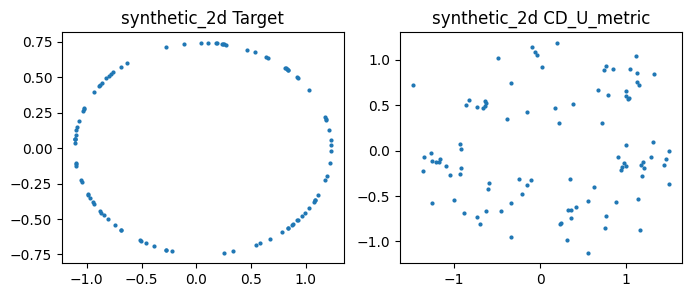

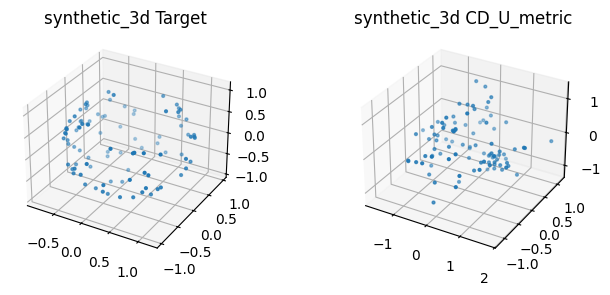

Hellinger2  Chamfer2
dataset      method                            
synthetic_2d CD_U            0.230690  0.027309
             CD_U_metric     0.280971  0.029144
             CD_W            0.228352  0.028644
             D2_exact        0.237036  0.029445
             M_U             0.230060  0.026768
             M_U_metric      0.306502  0.026306
             Mean            0.271459  0.030936
             Oracle_grid     0.000000  0.012415
             PCA_spectrum    0.264293  0.030247
synthetic_3d CD_U            0.159175  0.101701
             CD_U_metric     0.206993  0.106161
             CD_W            0.161164  0.104941
             D2_exact        0.161711  0.104916
             M_U             0.153554  0.099911
             M_U_metric      0.245056  0.113983
             Mean            0.183492  0.111395
             Oracle_grid     0.000000  0.077183
             PCA_spectrum    0.158854  0.099987

In [13]:
reconstruction=[]
for name,(R,yr,V,yv,Q,yq) in datasets.items():
    dim=R[0].shape[1];bins=10 if dim==3 else 20
    models=models_by_dataset[name];FV=transform_models(models,V);FQ=objects[name][1]
    H,_,diagR=voxel_targets(R,bins);Hv,_,diagV=voxel_targets(V,bins);Hq,canonical,diagQ=voxel_targets(Q,bins)
    diagQ.to_csv(OUT/f'{name}_pose_diagnostics.csv',index=False)
    predictions={'Mean':np.repeat(H.mean(0)[None],len(Q),axis=0),'Oracle_grid':Hq}
    for model in models:
        pred,alpha,scores=decode_fields(models[model]['gallery'],H,FV[model],Hv,FQ[model])
        predictions[model]=pred
        (OUT/f'{name}_{model}_decoder.json').write_text(json.dumps(dict(alpha=alpha,validation=scores,bins=bins,extent=3),indent=2))
    for model,P in predictions.items():
        for i,(p,h,target) in enumerate(zip(P,Hq,canonical)):
            cloud=sample_voxels(p,dim,bins=bins,n=N_POINTS,seed=stable_seed(SEED,str(i)))
            reconstruction.append(dict(dataset=name,method=model,object_id=i,Hellinger2=hellinger2(p,h),Chamfer2=chamfer2(cloud,target)))
    # Una inspección visual por dataset, misma muestra y ejes.
    fig=plt.figure(figsize=(8,3))
    for j,model in enumerate(['Target','CD_U_metric']):
        ax=fig.add_subplot(1,2,j+1,projection='3d' if dim==3 else None)
        cloud=canonical[0] if model=='Target' else sample_voxels(predictions[model][0],dim,bins=bins,n=N_POINTS,seed=0)
        ax.scatter(*cloud.T,s=4);ax.set_title(name+' '+model)
    plt.show()
reconstruction=pd.DataFrame(reconstruction);reconstruction.to_csv(OUT/'reconstruction_per_object.csv',index=False)
display(reconstruction.groupby(['dataset','method'])[['Hellinger2','Chamfer2']].mean())

## 12. Concordancia documental y cierre
No aprobar una cifra sólo porque se parece a la anterior. Exigir coincidencia de dataset, identidades, número de puntos, características, normalización, métrica, perturbaciones, clusterizador y convención de evaluación.

| Afirmación del documento | Evidencia actual / acción |
|---|---|
| El repositorio no tiene CD ni generadores 3D | Desactualizada: commit 3f1b5be ya los incluye. |
| Seis familias sintéticas por dimensión | A8 sí; repositorio actual: seis 2D y siete 3D, con otras familias. |
| 78 coordenadas CD en 3D | Se verifica; no implica que el procesamiento posterior sea idéntico. |
| CD supera momentos en limpio | No conclusión general; usar diferencia pareada e intervalo. |
| Ponderación mejora +.017/+.020 | Atribución corregida: esos deltas eran CD adaptado − momentos adaptados bajo sesgo. |
| Reconstrucción invierte CD | Incorrecto: decoder aprendido/heurístico y pérdida de pose; experimento nuevo aquí. |
| Validar ShapeNet | Pendiente, sin ejecución en esta notebook. |

**No implementado como réplica:** decoder A8, factorial histórico completo de ocho variantes, soporte/calibración de todos los escenarios históricos, CD-barrera y selección de K para CD en escenas 3D, todos los barridos de fase. Para eso hay que integrar los scripts y manifiestos archivados correspondientes; no sustituirlos silenciosamente. Esta notebook cubre el núcleo ejecutable y hace explícitas esas brechas.

Antes de tesis: congelar versión, ejecutar full, completar ModelNet, repetir por objeto, inspeccionar fallas, cerrar tablas desde CSV y marcar lo pendiente. Un intervalo que contiene cero no demuestra equivalencia. Ningún score smoke debe copiarse como hallazgo final.

In [14]:
inventory=[]
for p in sorted(OUT.iterdir()):
    if p.is_file():inventory.append(dict(file=p.name,bytes=p.stat().st_size,sha256=hashlib.sha256(p.read_bytes()).hexdigest()))
pd.DataFrame(inventory).to_csv(OUT/'inventory.csv',index=False)
status={'mathematical_checks':'executed','historical_csv_consistency':'executed',
        'synthetic_experiments':MODE,'modelnet':'executed' if modelnet_summaries else 'pending_local_data',
        'historical_A8_replication':'not_claimed','shapenet':'not_run','scene_3d':'new_spatial_CD_given_K_and_DBSCAN_unknown_K'}
(OUT/'status.json').write_text(json.dumps(status,indent=2))
display(pd.Series(status));print('Guardar notebook ejecutada junto con:',OUT)

Guardar notebook ejecutada junto con: /workspace/scratch/300c1df4e8f8/point-field/runs/20261119T180453630243Z


mathematical_checks                                              executed
historical_csv_consistency                                       executed
synthetic_experiments                                               smoke
modelnet                                               pending_local_data
historical_A8_replication                                     not_claimed
shapenet                                                          not_run
scene_3d                      new_spatial_CD_given_K_and_DBSCAN_unknown_K
dtype: object